NRK April 18 2025
RCSB-api full docs
https://rcsbapi.readthedocs.io/en/latest/search_api/query_construction.html#search-service-types


In [1]:
pip install rcsb-api

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.8/45.8 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 203.4/203.4 kB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 41.5 MB/s eta 0:00:00


In [2]:
from rcsbapi.search import TextQuery
from rcsbapi.search import SeqMotifQuery

## search for 9FY0

In [65]:
# Search for structures associated with the phrase "Hemoglobin"
query = TextQuery(value="9FY0")

# Execute the query by running it as a function
results = query()

# Results are returned as an iterator of result identifiers.
for rid in results:
    print(rid)

9FY0


# search for speciofic motif
GGCGUAAGCC- RNA

In [67]:
from rcsbapi.search import SeqMotifQuery

# Use SeqMotifQuery class and add parameters
query = SeqMotifQuery(
    "GGCGUAAGCC",
    pattern_type="regex",
    sequence_type="rna"
)

# query("polymer_entity") produces an iterator of IDs with return type polymer_entity
for polyid in query("polymer_entity"):
    print(polyid)


4R4P_1
4R4V_1
4V4N_38
4V6U_67
4V6W_83
5V3I_1
5XXB_1
6SKF_27
6SKG_27
6TH6_27
6XU6_59
6XU7_62
6XU8_69
8HKX_1
8HKY_2
8HKZ_2
8HL1_1
8HL2_2
8HL3_2
8HL4_2
8HL5_2
8WKP_1
8WQ2_1
8WQ4_1
9E71_3
9E7F_4
9FHL_1
9FRA_1
9FRK_1
9FRL_1
9FS6_1
9FS8_1
9FSF_1
9FY0_1


# search if 9FY0 pdb has specific sequence

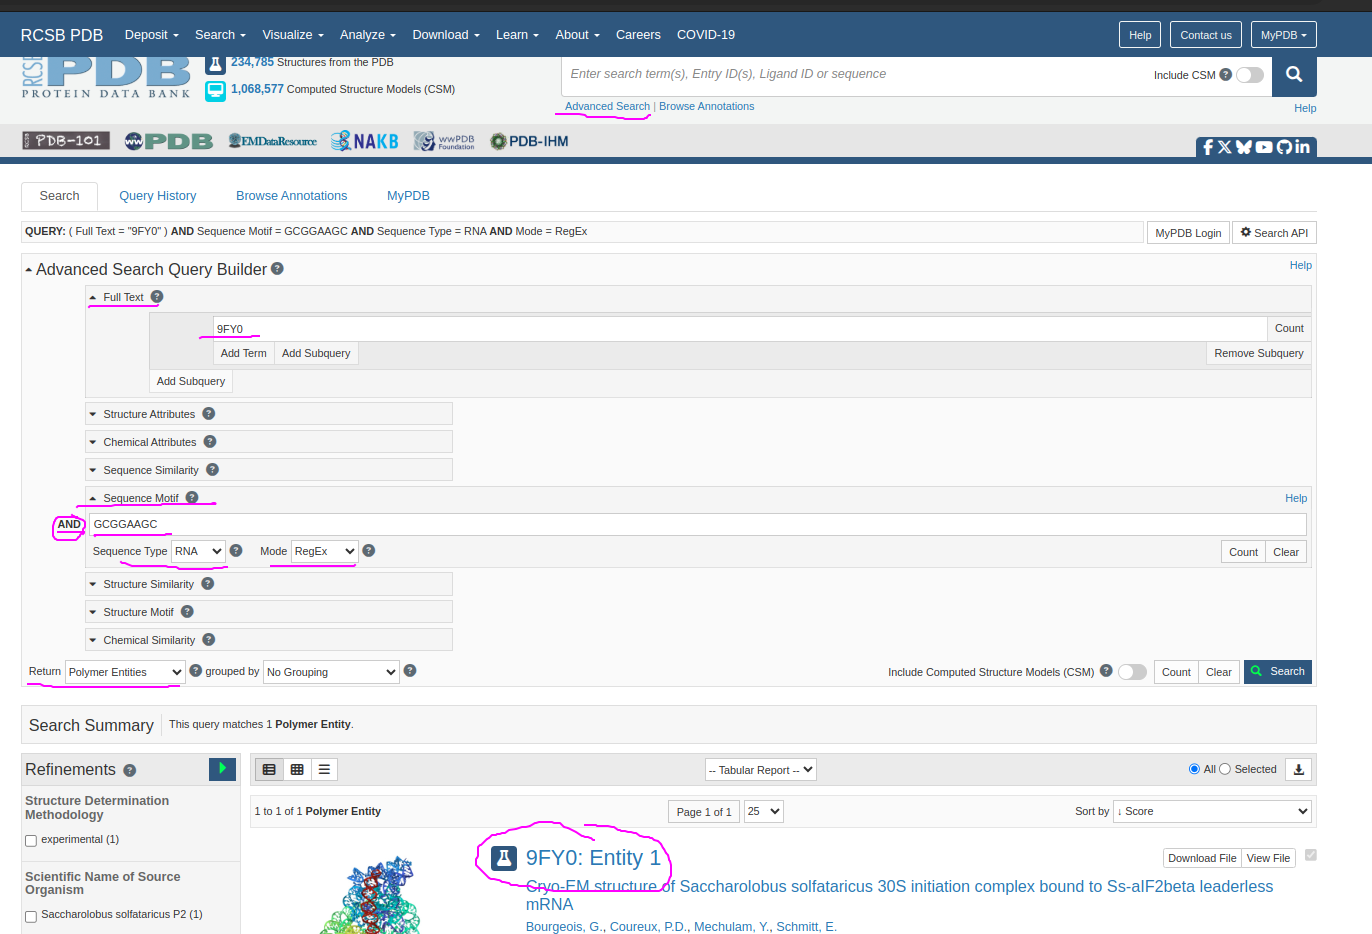



In [70]:
q1 = TextQuery(value="9FY0")

q2= SeqMotifQuery(
      "GGCGUAAGCC",
      pattern_type="regex",
      sequence_type="rna")

query = q1 & q2

list(query())

['9FY0']

# serach many PBD ID and check match

In [59]:
from rcsbapi.search import TextQuery
from rcsbapi.search import SeqMotifQuery
# List of item identifiers
items = ["9HC4", "9FY0", "9FSF", "9FS8", "9FS6", "9FRL", "9FRK", "9FRA", "9FHL", "9E7F", "9E71",
         "8S1U", "8S1P", "8QCQ", "8RDW", "8RDV", "8RD8", "8R55", "8QPP", "8BUU", "7UW1", "7UVZ",
         "7UVY", "7UVX", "7UVW", "7UVV", "7RYH", "7RYG", "7QV3", "7QV2"]

# Define the motif query once
motif_query = SeqMotifQuery(
    "GGCGUAAGCC",
    pattern_type="regex",
    sequence_type="rna"
)

# Loop through each item and apply the query
for item in items:
    text_query = TextQuery(value=item)
    combined_query = text_query & motif_query

    results = list(combined_query())

    if results:  # If there are any matches
        print(f"Match found in {item}: {results}")
    else:
        print(f"No match in {item}")


No match in 9HC4
Match found in 9FY0: ['9FY0']
Match found in 9FSF: ['9FSF']
Match found in 9FS8: ['9FS8']
Match found in 9FS6: ['9FS6']
Match found in 9FRL: ['9FRL']
Match found in 9FRK: ['9FRK']
Match found in 9FRA: ['9FRA']
Match found in 9FHL: ['9FHL']
Match found in 9E7F: ['9E7F']
Match found in 9E71: ['9E71']
No match in 8S1U
No match in 8S1P
No match in 8QCQ
No match in 8RDW
No match in 8RDV
No match in 8RD8
No match in 8R55
No match in 8QPP
No match in 8BUU
No match in 7UW1
No match in 7UVZ
No match in 7UVY
No match in 7UVX
No match in 7UVW
No match in 7UVV
No match in 7RYH
No match in 7RYG
No match in 7QV3
No match in 7QV2
